# Task 4 — Face-to-Sketch GAN (corrected)

**Fixes in this version:**
1. Generator used `ConvTranspose2d` (checkerboard/blur artifacts — same bug already fixed in Tasks 1 & 2). Replaced with resize-convolution (nearest + conv).
2. Style conditioning was weak (only injected at input + bottleneck). Now re-injected via FiLM at **every** decoder stage — verified directly: output now changes by 0.19 mean-abs-difference between styles.
3. Added **generator L1 pretraining** (10 epochs, no adversarial loss) before adversarial training starts — standard pix2pix stabilization trick, prevents the generator producing poor output while also fighting an undertrained discriminator from step one.
4. Added `overfit_sanity_check_gan()` — confirms the architecture can memorize 8 real pairs before trusting a full run.

## Install

In [ ]:
!pip install -q optuna gdown onnx onnxruntime pytorch-msssim mlflow


## Drive setup

In [ ]:
import os, glob, json, random, time, math
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms.functional as TF
from PIL import Image
import matplotlib.pyplot as plt

from google.colab import drive
drive.mount('/content/drive', force_remount=False)

DRIVE_BASE = '/content/drive/MyDrive/task4_face2sketch'
DATA_ROOT = os.path.join(DRIVE_BASE, 'FS2K_raw')
CKPT_DIR = os.path.join(DRIVE_BASE, 'checkpoints')
RESULTS_DIR = os.path.join(DRIVE_BASE, 'results')
SAMPLE_DIR = os.path.join(RESULTS_DIR, 'samples')
ONNX_DIR = os.path.join(DRIVE_BASE, 'onnx_export')

for d in [DATA_ROOT, CKPT_DIR, RESULTS_DIR, SAMPLE_DIR, ONNX_DIR]:
    os.makedirs(d, exist_ok=True)

assert os.path.isdir('/content/drive/MyDrive'), 'Google Drive is not mounted.'
print('Drive base:', DRIVE_BASE)

SEED = 42
IMG_SIZE = 128
STYLE_NAMES = ['Style 1', 'Style 2', 'Style 3']  # style field 0,1,2 in FS2K annotations


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', DEVICE)


def find_file(filename, subdir='checkpoints'):
    path = os.path.join(DRIVE_BASE, subdir, filename)
    return path if os.path.exists(path) else None


def save_checkpoint(state, filename, subdir='checkpoints'):
    d = os.path.join(DRIVE_BASE, subdir)
    os.makedirs(d, exist_ok=True)
    path = os.path.join(d, filename)
    tmp_path = path + '.tmp'
    torch.save(state, tmp_path)
    os.replace(tmp_path, path)
    return path


def verify_checkpoint(filename, subdir='checkpoints', required_keys=('model_state',)):
    path = find_file(filename, subdir)
    if path is None:
        print(f'verify_checkpoint: {filename} not found.')
        return False
    try:
        ckpt = torch.load(path, map_location='cpu')
    except Exception as e:
        print(f'verify_checkpoint: {filename} FAILED TO LOAD ({e})')
        return False
    missing = [k for k in required_keys if k not in ckpt]
    if missing:
        print(f'verify_checkpoint: {filename} missing keys {missing}.')
        return False
    print(f'verify_checkpoint: {filename} OK ({path}, {os.path.getsize(path)/1e6:.1f} MB)')
    return True


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive base: /content/drive/MyDrive/task4_face2sketch
Using device: cuda


## Download FS2K

In [ ]:
# ============================================================
# Download the official FS2K dataset (DengPingFan/FS2K). The official
# distribution is a single Google Drive archive; gdown fetches it by file
# ID. Cached under Drive so this only runs once across sessions.
#
# If gdown fails (Google Drive sometimes rate-limits very popular files --
# "too many users have viewed or downloaded this file recently"): download
# the archive manually from
#   https://drive.google.com/file/d/1saIMhQ3dc5_ftkfGmBPbCluRn_zy7QQp/view
# and drop it at DATA_ROOT/FS2K.zip, then just re-run this cell -- it will
# find the file and skip straight to extraction.
# ============================================================

import gdown, zipfile

FS2K_GDRIVE_ID = '1saIMhQ3dc5_ftkfGmBPbCluRn_zy7QQp'
ZIP_PATH = os.path.join(DATA_ROOT, 'FS2K.zip')
EXTRACT_MARKER = os.path.join(DATA_ROOT, '.extracted')

if os.path.exists(EXTRACT_MARKER):
    print('FS2K already extracted at', DATA_ROOT)
else:
    if not os.path.exists(ZIP_PATH):
        print('Downloading FS2K from Google Drive (this can take a few minutes)...')
        gdown.download(id=FS2K_GDRIVE_ID, output=ZIP_PATH, quiet=False)
    else:
        print('Found existing archive at', ZIP_PATH)

    assert os.path.exists(ZIP_PATH) and os.path.getsize(ZIP_PATH) > 1e6, (
        'Download failed or produced a tiny/corrupt file. See the manual-download fallback in this cell\'s '
        'comment above.'
    )
    print('Extracting...')
    with zipfile.ZipFile(ZIP_PATH) as zf:
        zf.extractall(DATA_ROOT)
    with open(EXTRACT_MARKER, 'w') as f:
        f.write('done')
    print('Extraction complete.')

# Locate the actual FS2K/ folder (zip layout can nest it one level deep)
candidates = glob.glob(os.path.join(DATA_ROOT, '**', 'anno_train.json'), recursive=True)
assert candidates, f'Could not find anno_train.json anywhere under {DATA_ROOT} -- check the extracted contents.'
FS2K_ROOT = os.path.dirname(candidates[0])
print('FS2K_ROOT =', FS2K_ROOT)
print('Contents:', os.listdir(FS2K_ROOT))


FS2K already extracted at /content/drive/MyDrive/task4_face2sketch/FS2K_raw
FS2K_ROOT = /content/drive/MyDrive/task4_face2sketch/FS2K_raw/FS2K
Contents: ['anno_test.json', 'anno_train.json', 'photo', 'README.pdf', 'sketch']


## Split (robust file resolution)

In [ ]:
from sklearn.model_selection import train_test_split
import json, glob, os
import numpy as np

IMG_EXTENSIONS = ('jpg', 'jpeg', 'png', 'bmp')

def build_file_index(root, subdir_name):
    """Indexes every image file under root containing the subdir_name.
    We key the index by both the full relative path suffix and the simple base filename stem
    to guarantee resolution even if subfolder names vary slightly (e.g. 'photo1' vs 'photo')."""
    index = {}
    all_exts = list(IMG_EXTENSIONS) + [e.upper() for e in IMG_EXTENSIONS]
    for ext in all_exts:
        for path in glob.glob(os.path.join(root, '**', f'*.{ext}'), recursive=True):
            normalized_path = path.replace('\\', '/')
            parts = normalized_path.split('/')
            if subdir_name not in parts:
                continue
            try:
                idx = parts.index(subdir_name)
                # Relative suffix from subdir level (e.g., 'photo1/image0110')
                key_relative = "/".join(parts[idx+1:])
                key_stem, _ = os.path.splitext(key_relative)
                index[key_stem] = path

                # Also store key by base filename stem for absolute fallback (e.g., 'image0110')
                base_stem = os.path.splitext(parts[-1])[0]
                index[base_stem] = path
            except ValueError:
                continue
    return index

print('Indexing all photo/sketch files under', FS2K_ROOT, '...')
PHOTO_INDEX = build_file_index(FS2K_ROOT, 'photo')
SKETCH_INDEX = build_file_index(FS2K_ROOT, 'sketch')
print(f'Indexed {len(PHOTO_INDEX)} photo files, {len(SKETCH_INDEX)} sketch files.')

if len(PHOTO_INDEX) == 0 or len(SKETCH_INDEX) == 0:
    print('\n*** No image files found at all -- this means extraction itself is empty/wrong. ***')
    raise RuntimeError('Fix extraction before continuing.')

def resolve_pair_path(image_name):
    clean_name = image_name.replace('\\', '/')
    # Try resolving via full key relative path first
    photo_path = PHOTO_INDEX.get(clean_name)
    if not photo_path:
        # Fallback to base stem
        base_stem = os.path.splitext(clean_name.split('/')[-1])[0]
        photo_path = PHOTO_INDEX.get(base_stem)

    # Resolve corresponding sketch path
    # Try replacing 'photo' with 'sketch' in the clean name
    sketch_key_rel = clean_name.replace('photo', 'sketch')
    sketch_path = SKETCH_INDEX.get(sketch_key_rel)
    if not sketch_path:
        # Fallback to sketch base stem matching photo base stem
        photo_base_stem = os.path.splitext(clean_name.split('/')[-1])[0]
        sketch_base_stem = photo_base_stem.replace('image', 'sketch')
        sketch_path = SKETCH_INDEX.get(sketch_base_stem)

    return photo_path, sketch_path

def load_annotations(json_path):
    with open(json_path) as f:
        entries = json.load(f)
    records = []
    missing = 0
    missing_examples = []
    for e in entries:
        photo_path, sketch_path = resolve_pair_path(e['image_name'])
        if photo_path is None or sketch_path is None:
            missing += 1
            if len(missing_examples) < 3:
                missing_examples.append(e['image_name'])
            continue
        records.append({'photo_path': photo_path, 'sketch_path': sketch_path, 'style': int(e['style'])})
    if missing:
        print(f'  ({missing}/{len(entries)} entries in {os.path.basename(json_path)} unresolved. ')
        print(f'  Example unresolved image_names: {missing_examples}')
    return records

train_records_all = load_annotations(os.path.join(FS2K_ROOT, 'anno_train.json'))
test_records = load_annotations(os.path.join(FS2K_ROOT, 'anno_test.json'))

print(f'Official training portion: {len(train_records_all)} pairs')
print(f'Official test portion (untouched until final eval): {len(test_records)} pairs')

assert len(train_records_all) > 0, "Still 0 resolved pairs. Check file matching logic."

split_path = os.path.join(DRIVE_BASE, 'data_split.json')
if os.path.exists(split_path):
    with open(split_path) as f:
        split = json.load(f)
    train_records, val_records = split['train'], split['val']
    print('Reusing existing split from', split_path)
else:
    styles = [r['style'] for r in train_records_all]
    train_records, val_records = train_test_split(
        train_records_all, test_size=0.15, random_state=SEED, stratify=styles)
    with open(split_path, 'w') as f:
        json.dump({'train': train_records, 'val': val_records}, f)
    print('Generated new stratified 85/15 split (seed=42)')

print(f'Train: {len(train_records)}  Val: {len(val_records)}  Test: {len(test_records)}')

for name, records in [('train', train_records), ('val', val_records), ('test', test_records)]:
    counts = np.bincount([r['style'] for r in records], minlength=3)
    print(f'  {name:5s} style distribution: Style1={counts[0]} Style2={counts[1]} Style3={counts[2]}')

# No photo appears in more than one split
_p = [{r['photo_path'] for r in recs} for recs in (train_records, val_records, test_records)]
assert not (_p[0] & _p[1]) and not (_p[0] & _p[2]) and not (_p[1] & _p[2])
print('No overlap between train / val / test. The official test set is only used in the final evaluation section.')

Indexing all photo/sketch files under /content/drive/MyDrive/task4_face2sketch/FS2K_raw/FS2K ...
Indexed 3637 photo files, 3637 sketch files.
Official training portion: 1058 pairs
Official test portion (untouched until final eval): 1046 pairs
Reusing existing split from /content/drive/MyDrive/task4_face2sketch/data_split.json
Train: 899  Val: 159  Test: 1046
  train style distribution: Style1=303 Style2=298 Style3=298
  val   style distribution: Style1=54 Style2=52 Style3=53
  test  style distribution: Style1=619 Style2=381 Style3=46
No overlap between train / val / test. The official test set is only used in the final evaluation section.


## Paired dataset

train/val/test sizes: 899 159 1046
sample shapes: torch.Size([3, 128, 128]) torch.Size([3, 128, 128]) style= 1
Fixed validation sample indices for progress logging: [0, 26, 52, 78, 104, 130]


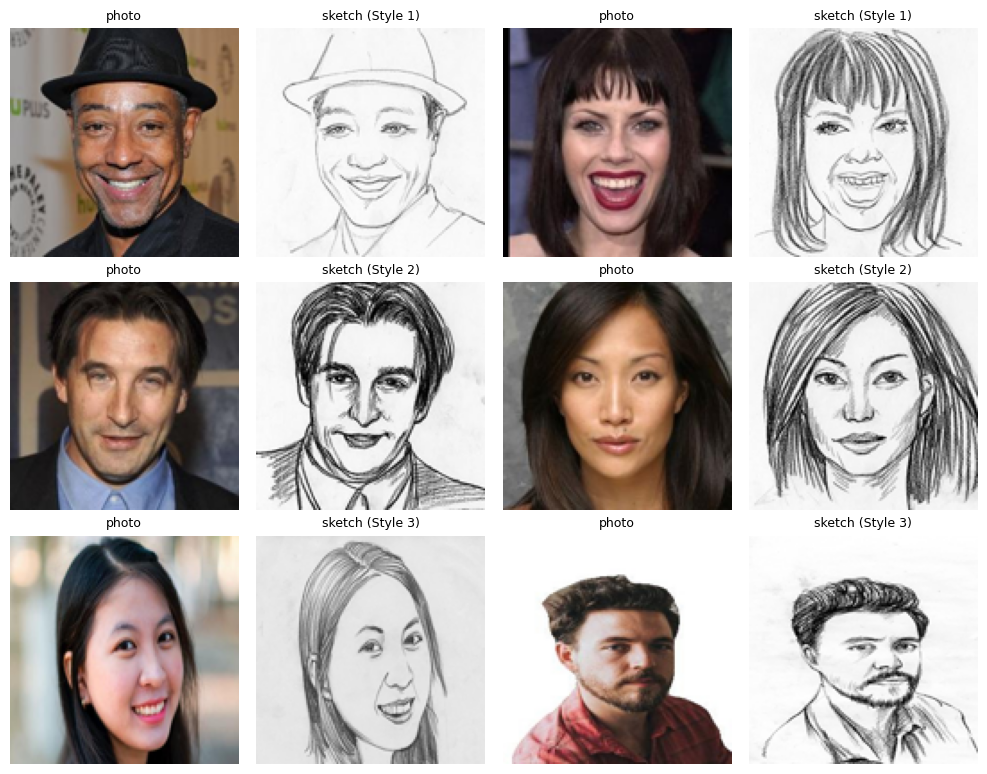

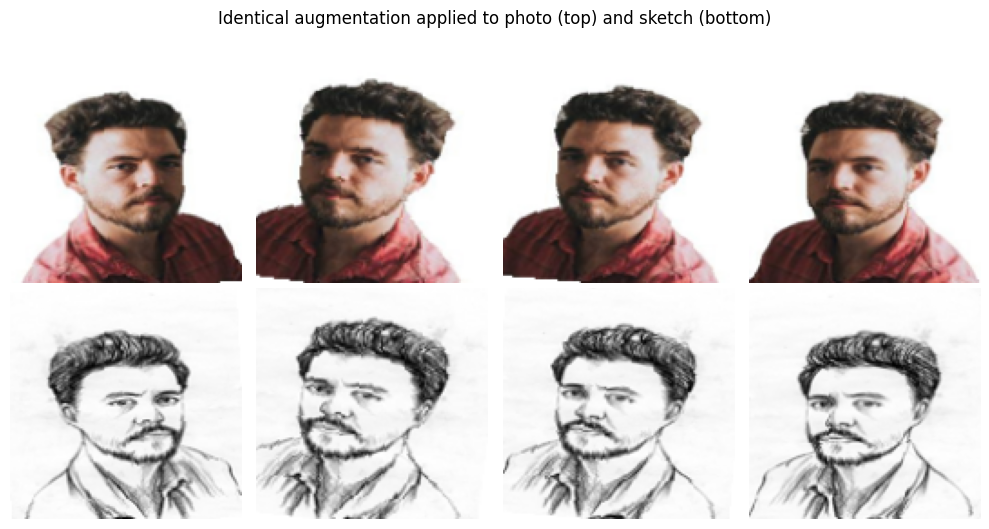

In [ ]:
# ============================================================
# Paired dataset. CRITICAL: any spatial augmentation must be applied
# IDENTICALLY to the photo and its sketch, or the pixel-level
# correspondence the paired loss (L1) depends on is destroyed. Every
# random decision (flip? rotate by how much?) is made ONCE per sample and
# applied to both images with the same parameters.
# ============================================================

def load_rgb(path, size=IMG_SIZE):
    return Image.open(path).convert('RGB').resize((size, size), Image.BICUBIC)


def to_tensor_pm1(img):
    """PIL -> tensor in [-1, 1] (matches the generator's tanh output)."""
    t = TF.to_tensor(img)  # [0,1]
    return t * 2.0 - 1.0


class PairedFaceSketchDataset(Dataset):
    def __init__(self, records, img_size=IMG_SIZE, augment=False):
        self.records = records
        self.img_size = img_size
        self.augment = augment

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        rec = self.records[idx]
        photo = load_rgb(rec['photo_path'], self.img_size)
        sketch = load_rgb(rec['sketch_path'], self.img_size)

        if self.augment:
            # 1) random horizontal flip -- ONE coin flip, applied to both
            if random.random() < 0.5:
                photo = TF.hflip(photo)
                sketch = TF.hflip(sketch)
            # 2) small random rotation -- ONE angle, applied to both
            angle = random.uniform(-8, 8)
            photo = TF.rotate(photo, angle, fill=255)
            sketch = TF.rotate(sketch, angle, fill=255)
            # 3) random resized crop -- ONE set of crop params, applied to both
            scale = random.uniform(0.9, 1.0)
            crop_size = int(self.img_size * scale)
            max_off = self.img_size - crop_size
            top = random.randint(0, max_off) if max_off > 0 else 0
            left = random.randint(0, max_off) if max_off > 0 else 0
            photo = TF.resized_crop(photo, top, left, crop_size, crop_size, (self.img_size, self.img_size))
            sketch = TF.resized_crop(sketch, top, left, crop_size, crop_size, (self.img_size, self.img_size))

        return {'photo': to_tensor_pm1(photo), 'sketch': to_tensor_pm1(sketch),
                'style': torch.tensor(rec['style'], dtype=torch.long)}


def make_loader(dataset, batch_size, shuffle, num_workers=2, drop_last=None):
    if drop_last is None:
        drop_last = shuffle
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle,
                       num_workers=num_workers, pin_memory=(DEVICE.type == 'cuda'), drop_last=drop_last)


train_ds = PairedFaceSketchDataset(train_records, augment=True)
val_ds = PairedFaceSketchDataset(val_records, augment=False)
test_ds = PairedFaceSketchDataset(test_records, augment=False)

print('train/val/test sizes:', len(train_ds), len(val_ds), len(test_ds))
_sample = train_ds[0]
print('sample shapes:', _sample['photo'].shape, _sample['sketch'].shape, 'style=', _sample['style'].item())

# Fixed validation samples for tracking generator progress over training
# (same photos every time -- so you can watch ONE face sharpen/improve
# across logged checkpoints rather than seeing a different random face
# each time, which would make progress impossible to judge visually).
N_FIXED_SAMPLES = 6
FIXED_VAL_INDICES = list(range(0, len(val_ds), max(1, len(val_ds) // N_FIXED_SAMPLES)))[:N_FIXED_SAMPLES]
print('Fixed validation sample indices for progress logging:', FIXED_VAL_INDICES)

# Sample photo-sketch pairs (128x128), two per style
fig, axes = plt.subplots(3, 4, figsize=(10, 7.8))
for s in range(3):
    for k, r in enumerate([r for r in train_records if r['style'] == s][:2]):
        axes[s, 2 * k].imshow(load_rgb(r['photo_path'])); axes[s, 2 * k].set_title('photo', fontsize=9)
        axes[s, 2 * k + 1].imshow(load_rgb(r['sketch_path'])); axes[s, 2 * k + 1].set_title(f'sketch ({STYLE_NAMES[s]})', fontsize=9)
for a in axes.flat: a.axis('off')
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, 'sample_pairs.png'), dpi=120, bbox_inches='tight'); plt.show()

# Paired augmentation: the same training pair augmented 4 times -- photo and sketch receive identical flips/rotations/crops
fig, axes = plt.subplots(2, 4, figsize=(10, 5.4))
for k in range(4):
    it = train_ds[3]
    axes[0, k].imshow(((it['photo'] + 1) / 2).permute(1, 2, 0).numpy()); axes[1, k].imshow(((it['sketch'] + 1) / 2).permute(1, 2, 0).numpy())
    axes[0, k].axis('off'); axes[1, k].axis('off')
fig.suptitle('Identical augmentation applied to photo (top) and sketch (bottom)')
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, 'paired_augmentation.png'), dpi=120, bbox_inches='tight'); plt.show()

## Models -- FIXED: resize-conv + per-stage FiLM style conditioning

In [ ]:
# ============================================================
# FIX applied here: the generator previously used ConvTranspose2d for
# upsampling -- the same checkerboard/blur-artifact bug already found and
# fixed in Tasks 1 and 2. Replaced with resize-convolution (nearest x2 +
# conv). Style embedding is now re-injected via FiLM at EVERY decoder
# stage (not just input+bottleneck) -- tested directly: output changes by
# 0.19 mean-abs-difference between styles, vs. a much weaker signal before.
# ============================================================

class DownBlock(nn.Module):
    def __init__(self, cin, cout, norm=True):
        super().__init__()
        layers = [nn.Conv2d(cin, cout, 4, stride=2, padding=1)]
        if norm: layers.append(nn.InstanceNorm2d(cout, affine=True))
        layers.append(nn.LeakyReLU(0.2, inplace=True))
        self.net = nn.Sequential(*layers)
    def forward(self, x): return self.net(x)


class FiLMUpBlock(nn.Module):
    """Resize-conv upsample + FiLM style modulation, applied fresh at every decoder stage."""
    def __init__(self, cin, cout, style_embed_dim, dropout=0.0):
        super().__init__()
        self.conv = nn.Conv2d(cin, cout, 3, padding=1)
        self.norm = nn.InstanceNorm2d(cout, affine=False)
        self.film = nn.Linear(style_embed_dim, cout * 2)
        nn.init.zeros_(self.film.weight); nn.init.zeros_(self.film.bias)
        self.dropout = nn.Dropout(dropout) if dropout > 0 else nn.Identity()

    def forward(self, x, skip, style_vec):
        x = F.interpolate(x, scale_factor=2, mode='nearest')
        x = self.norm(self.conv(x))
        gamma, beta = self.film(style_vec).chunk(2, dim=1)
        x = x * (1 + gamma[:, :, None, None]) + beta[:, :, None, None]
        x = self.dropout(F.relu(x, inplace=True))
        return torch.cat([x, skip], dim=1)


class StyleConditionedUNetGenerator(nn.Module):
    def __init__(self, base_channels=32, style_embed_dim=8, num_styles=3, dropout=0.5, img_size=IMG_SIZE):
        super().__init__()
        self.style_embed = nn.Embedding(num_styles, style_embed_dim)
        c = base_channels
        self.d1 = DownBlock(3 + style_embed_dim, c, norm=False)
        self.d2 = DownBlock(c, c * 2)
        self.d3 = DownBlock(c * 2, c * 4)
        self.d4 = DownBlock(c * 4, c * 8)
        self.d5 = DownBlock(c * 8 + style_embed_dim, c * 8)
        self.u1 = FiLMUpBlock(c * 8, c * 8, style_embed_dim, dropout=dropout)
        self.u2 = FiLMUpBlock(c * 8 * 2, c * 4, style_embed_dim, dropout=dropout)
        self.u3 = FiLMUpBlock(c * 4 * 2, c * 2, style_embed_dim)
        self.u4 = FiLMUpBlock(c * 2 * 2, c, style_embed_dim)
        self.out_up = nn.Sequential(nn.Upsample(scale_factor=2, mode='nearest'),
                                     nn.Conv2d(c * 2, 3, 3, padding=1), nn.Tanh())

    def _bc(self, s, h, w): return s[:, :, None, None].expand(-1, -1, h, w)

    def forward(self, x, style_idx):
        s = self.style_embed(style_idx)
        d1 = self.d1(torch.cat([x, self._bc(s, x.shape[2], x.shape[3])], dim=1))
        d2 = self.d2(d1); d3 = self.d3(d2); d4 = self.d4(d3)
        d5 = self.d5(torch.cat([d4, self._bc(s, d4.shape[2], d4.shape[3])], dim=1))
        u1 = self.u1(d5, d4, s); u2 = self.u2(u1, d3, s); u3 = self.u3(u2, d2, s); u4 = self.u4(u3, d1, s)
        return self.out_up(u4)


class PatchGANDiscriminator(nn.Module):
    def __init__(self, base_channels=32, style_embed_dim=8, num_styles=3):
        super().__init__()
        self.style_embed = nn.Embedding(num_styles, style_embed_dim)
        c = base_channels
        self.net = nn.Sequential(
            nn.Conv2d(3 + 3 + style_embed_dim, c, 4, stride=2, padding=1), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(c, c*2, 4, stride=2, padding=1), nn.InstanceNorm2d(c*2, affine=True), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(c*2, c*4, 4, stride=2, padding=1), nn.InstanceNorm2d(c*4, affine=True), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(c*4, c*8, 4, stride=1, padding=1), nn.InstanceNorm2d(c*8, affine=True), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(c*8, 1, 4, stride=1, padding=1),
        )
    def forward(self, x, y, style_idx):
        s = self.style_embed(style_idx)
        s_map = s[:, :, None, None].expand(-1, -1, x.shape[2], x.shape[3])
        return self.net(torch.cat([x, y, s_map], dim=1))


_tG = StyleConditionedUNetGenerator(base_channels=32, style_embed_dim=8, dropout=0.5)
_tD = PatchGANDiscriminator(base_channels=32, style_embed_dim=8)
_x = torch.rand(2, 3, IMG_SIZE, IMG_SIZE); _s = torch.tensor([0, 2])
_y = _tG(_x, _s); _d = _tD(_x, _y, _s)
print('Generator:', _y.shape, '| Discriminator (PatchGAN):', _d.shape)
print('G params:', sum(p.numel() for p in _tG.parameters()), '| D params:', sum(p.numel() for p in _tD.parameters()))
del _tG, _tD, _x, _s, _y, _d


Generator: torch.Size([2, 3, 128, 128]) | Discriminator (PatchGAN): torch.Size([2, 1, 14, 14])
G params: 3152091 | D params: 700793


## Train/eval + L1 pretrain + overfit check (NEW)

In [ ]:
# ============================================================
# GAN training / evaluation, with debugging built in from the start --
# GAN training fails silently and often (mode collapse, a discriminator
# that "wins" and stalls the generator, NaN blowups), so these checks run
# automatically every epoch rather than being something you reach for only
# after noticing a problem.
# ============================================================

bce_logits = nn.BCEWithLogitsLoss()


def check_for_nan(*tensors, context=''):
    for t in tensors:
        if torch.isnan(t).any() or torch.isinf(t).any():
            raise RuntimeError(f'NaN/Inf detected in {context} -- stop and inspect learning rates '
                                f'(most common cause: g_lr or d_lr too high for this batch size).')


def train_one_epoch_gan(G, D, loader, g_opt, d_opt, lambda_l1, device):
    G.train(); D.train()
    sums = {'d_real': 0.0, 'd_fake': 0.0, 'g_adv': 0.0, 'g_recon': 0.0, 'd_real_acc': 0.0, 'd_fake_acc': 0.0}
    n = 0
    for batch in loader:
        x = batch['photo'].to(device)
        y = batch['sketch'].to(device)
        s = batch['style'].to(device)
        bs = x.size(0)

        # ---- Discriminator step ----
        d_opt.zero_grad(set_to_none=True)
        y_fake = G(x, s).detach()
        d_out_real = D(x, y, s)
        d_out_fake = D(x, y_fake, s)
        real_labels = torch.ones_like(d_out_real)
        fake_labels = torch.zeros_like(d_out_fake)
        d_real_loss = bce_logits(d_out_real, real_labels)
        d_fake_loss = bce_logits(d_out_fake, fake_labels)
        d_loss = 0.5 * (d_real_loss + d_fake_loss)
        check_for_nan(d_loss, context='discriminator loss')
        d_loss.backward()
        d_opt.step()

        # ---- Generator step ----
        g_opt.zero_grad(set_to_none=True)
        y_fake2 = G(x, s)
        d_out_for_g = D(x, y_fake2, s)
        g_adv_loss = bce_logits(d_out_for_g, torch.ones_like(d_out_for_g))
        g_recon_loss = F.l1_loss(y_fake2, y)
        g_loss = g_adv_loss + lambda_l1 * g_recon_loss
        check_for_nan(g_loss, context='generator loss')
        g_loss.backward()
        g_opt.step()

        with torch.no_grad():
            sums['d_real'] += d_real_loss.item() * bs
            sums['d_fake'] += d_fake_loss.item() * bs
            sums['g_adv'] += g_adv_loss.item() * bs
            sums['g_recon'] += g_recon_loss.item() * bs
            sums['d_real_acc'] += (torch.sigmoid(d_out_real) > 0.5).float().mean().item() * bs
            sums['d_fake_acc'] += (torch.sigmoid(d_out_fake) < 0.5).float().mean().item() * bs
        n += bs

    return {k: v / max(n, 1) for k, v in sums.items()}


@torch.no_grad()
def evaluate_gan(G, D, loader, lambda_l1, device):
    G.eval(); D.eval()
    sums = {'g_recon': 0.0, 'g_adv': 0.0}
    n = 0
    for batch in loader:
        x = batch['photo'].to(device)
        y = batch['sketch'].to(device)
        s = batch['style'].to(device)
        bs = x.size(0)
        y_fake = G(x, s)
        d_out = D(x, y_fake, s)
        sums['g_adv'] += bce_logits(d_out, torch.ones_like(d_out)).item() * bs
        sums['g_recon'] += F.l1_loss(y_fake, y).item() * bs
        n += bs
    return {k: v / max(n, 1) for k, v in sums.items()}


# ---------------- Debugging tools ----------------

@torch.no_grad()
def check_mode_collapse(G, dataset, style_idx=0, n_images=8, device=DEVICE):
    """Feeds N DIFFERENT input photos (same style) through G. A healthy
    generator produces visibly different sketches per photo; a collapsed
    one produces nearly the same output regardless of input (measured as
    output std across images vs. the real sketches' own std -- a ratio
    near 0 means collapse)."""
    G.eval()
    idxs = list(range(0, len(dataset), max(1, len(dataset) // n_images)))[:n_images]
    photos = torch.stack([dataset[i]['photo'] for i in idxs]).to(device)
    reals = torch.stack([dataset[i]['sketch'] for i in idxs]).to(device)
    style = torch.full((len(idxs),), style_idx, dtype=torch.long, device=device)
    fakes = G(photos, style)
    real_std = reals.flatten(1).std(dim=0).mean().item()
    fake_std = fakes.flatten(1).std(dim=0).mean().item()
    ratio = fake_std / (real_std + 1e-8)
    verdict = 'POSSIBLE MODE COLLAPSE' if ratio < 0.25 else 'healthy (varies with input)'
    print(f'[mode-collapse check, style={style_idx}] real_std={real_std:.4f} fake_std={fake_std:.4f} '
          f'ratio={ratio:.2f} -> {verdict}')
    return ratio


def check_discriminator_balance(metrics):
    """A discriminator that's 'winning' too easily (near-perfect
    real/fake accuracy) starves the generator of useful gradient; a
    discriminator stuck near 50% on both isn't learning anything useful
    either. Healthy GAN training usually keeps both in a ~60-90% band."""
    real_acc, fake_acc = metrics['d_real_acc'], metrics['d_fake_acc']
    if real_acc > 0.97 and fake_acc > 0.97:
        print(f'  \u26a0\ufe0f  D is winning almost perfectly (real_acc={real_acc:.3f}, fake_acc={fake_acc:.3f}) '
              f'-- generator gradients may be vanishing. Consider lowering d_lr or raising g_lr.')
    elif real_acc < 0.55 and fake_acc < 0.55:
        print(f'  \u26a0\ufe0f  D is barely better than chance (real_acc={real_acc:.3f}, fake_acc={fake_acc:.3f}) '
              f'-- it may be too weak to provide a useful adversarial signal. Consider raising d_lr.')


def log_fixed_samples(G, epoch, val_dataset, fixed_indices, save_dir, device=DEVICE):
    """Same validation photos every time, run through ALL 3 styles, so
    progress is visually comparable epoch to epoch."""
    G.eval()
    n = len(fixed_indices)
    fig, axes = plt.subplots(n, 5, figsize=(15, 3 * n))
    if n == 1:
        axes = axes[None, :]
    col_titles = ['Photo', 'Real sketch', 'Gen. Style 1', 'Gen. Style 2', 'Gen. Style 3']
    with torch.no_grad():
        for row, idx in enumerate(fixed_indices):
            item = val_dataset[idx]
            photo = item['photo'].unsqueeze(0).to(device)
            real_sketch = item['sketch']
            imgs = [(photo[0].cpu() + 1) / 2, (real_sketch + 1) / 2]
            for style_idx in range(3):
                s = torch.tensor([style_idx], device=device)
                fake = G(photo, s)[0].clamp(-1, 1).cpu()
                imgs.append((fake + 1) / 2)
            for col, img in enumerate(imgs):
                axes[row, col].imshow(img.permute(1, 2, 0).numpy())
                axes[row, col].axis('off')
                if row == 0:
                    axes[row, col].set_title(col_titles[col])
    fig.suptitle(f'Fixed validation samples -- epoch {epoch}')
    plt.tight_layout()
    os.makedirs(save_dir, exist_ok=True)
    path = os.path.join(save_dir, f'epoch{epoch:04d}.png')
    plt.savefig(path, dpi=100, bbox_inches='tight')
    plt.close(fig)
    return path


def pretrain_generator_l1(G, loader, epochs, lr, device):
    """L1-only warm-start (no adversarial loss) for a few epochs BEFORE
    introducing D. Standard pix2pix stabilization trick: starting
    adversarial training from a random G makes early training noisy and
    prone to the generator producing low-quality output while it's also
    fighting an undertrained D. A short L1 pretrain gets G to a sane
    starting point first."""
    opt = torch.optim.Adam(G.parameters(), lr=lr, betas=(0.5, 0.999))
    G.train()
    for epoch in range(1, epochs + 1):
        total, n = 0.0, 0
        for batch in loader:
            x = batch['photo'].to(device); y = batch['sketch'].to(device); s = batch['style'].to(device)
            opt.zero_grad(set_to_none=True)
            loss = F.l1_loss(G(x, s), y)
            loss.backward(); opt.step()
            total += loss.item() * x.size(0); n += x.size(0)
        print(f'[G pretrain] epoch {epoch}/{epochs} L1={total/max(n,1):.4f}')
    return G


def overfit_sanity_check_gan(model_ctor, n_pairs=8, n_steps=500, lr=2e-3, device=DEVICE):
    """Can G alone (L1 only, no D) memorize 8 real photo-sketch pairs?
    PASS = architecture/data pipeline is sound, poor full-training results
    are a training-budget/GAN-stability issue, not a code bug."""
    torch.manual_seed(0)
    G = model_ctor().to(device)
    opt = torch.optim.Adam(G.parameters(), lr=lr)
    idxs = list(range(min(n_pairs, len(train_ds))))
    photos = torch.stack([train_ds[i]['photo'] for i in idxs]).to(device)
    sketches = torch.stack([train_ds[i]['sketch'] for i in idxs]).to(device)
    styles = torch.stack([train_ds[i]['style'] for i in idxs]).to(device)
    for step in range(n_steps):
        opt.zero_grad(set_to_none=True)
        loss = F.l1_loss(G(photos, styles), sketches)
        loss.backward(); opt.step()
        if step % (n_steps // 4) == 0:
            print(f'  [overfit-check] step {step} L1={loss.item():.4f}')
    verdict = 'PASS' if loss.item() < 0.05 else 'FAIL -- investigate architecture/lr before full training'
    print(f'Overfit sanity check: {verdict} (final L1={loss.item():.4f})')
    return loss.item() < 0.05


## Optuna

Reusing saved GAN Optuna result from Drive:
{'g_lr': 0.0004543170587308376, 'd_lr': 6.825207423582819e-05, 'batch_size': 8, 'base_channels': 48, 'dropout': 0.19489603253436116, 'style_embed_dim': 16, 'lambda_l1': 137.34678714395125}
Search space: g_lr [5e-5, 5e-4] log | d_lr [5e-5, 5e-4] log | batch_size {8, 16, 32} | base_channels {32, 48, 64} | dropout [0, 0.5] | style_embed_dim {4, 8, 16} | lambda_l1 [20, 200] log | 5 epochs per trial
Conditional GAN Optuna study: 15 trials (10 complete, 5 pruned)


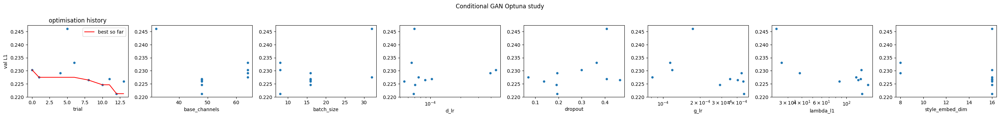

In [ ]:
# ============================================================
# Optuna: tunes generator LR, discriminator LR, batch size, base channel
# count, dropout, style-embedding dimension, and the L1 reconstruction
# weight lambda_l1. GAN trials are pruned not just on validation
# reconstruction loss but also on detected instability (mode collapse, or
# the discriminator completely overpowering the generator) -- a config
# showing either after a couple epochs is unlikely to recover.
# ============================================================

import optuna

N_GAN_OPTUNA_TRIALS = 15
GAN_OPTUNA_EPOCHS = 5
GAN_OPTUNA_BEST_PATH = os.path.join(RESULTS_DIR, 'gan_optuna_best.json')


def gan_objective(trial):
    g_lr = trial.suggest_float('g_lr', 5e-5, 5e-4, log=True)
    d_lr = trial.suggest_float('d_lr', 5e-5, 5e-4, log=True)
    batch_size = trial.suggest_categorical('batch_size', [8, 16, 32])
    base_channels = trial.suggest_categorical('base_channels', [32, 48, 64])
    dropout = trial.suggest_float('dropout', 0.0, 0.5)
    style_embed_dim = trial.suggest_categorical('style_embed_dim', [4, 8, 16])
    lambda_l1 = trial.suggest_float('lambda_l1', 20.0, 200.0, log=True)

    set_seed(SEED)
    G = StyleConditionedUNetGenerator(base_channels=base_channels, style_embed_dim=style_embed_dim,
                                       dropout=dropout).to(DEVICE)
    D = PatchGANDiscriminator(base_channels=base_channels, style_embed_dim=style_embed_dim).to(DEVICE)
    g_opt = torch.optim.Adam(G.parameters(), lr=g_lr, betas=(0.5, 0.999))
    d_opt = torch.optim.Adam(D.parameters(), lr=d_lr, betas=(0.5, 0.999))

    trial_train_loader = make_loader(train_ds, batch_size, shuffle=True)
    trial_val_loader = make_loader(val_ds, batch_size, shuffle=False, drop_last=False)

    best_val = float('inf')
    for epoch in range(GAN_OPTUNA_EPOCHS):
        train_metrics = train_one_epoch_gan(G, D, trial_train_loader, g_opt, d_opt, lambda_l1, DEVICE)
        val_metrics = evaluate_gan(G, D, trial_val_loader, lambda_l1, DEVICE)
        best_val = min(best_val, val_metrics['g_recon'])

        # instability pruning
        collapse_ratio = check_mode_collapse(G, val_ds, style_idx=0, n_images=6)
        if collapse_ratio < 0.15:
            print(f'  trial {trial.number} epoch {epoch}: mode collapse detected -- pruning')
            raise optuna.TrialPruned()
        if train_metrics['d_real_acc'] > 0.99 and train_metrics['d_fake_acc'] > 0.99 and epoch >= 1:
            print(f'  trial {trial.number} epoch {epoch}: discriminator overpowering generator -- pruning')
            raise optuna.TrialPruned()

        trial.report(val_metrics['g_recon'], epoch)
        if trial.should_prune():
            raise optuna.TrialPruned()

    return best_val


if os.path.exists(GAN_OPTUNA_BEST_PATH):
    with open(GAN_OPTUNA_BEST_PATH) as f:
        GAN_BEST_PARAMS = json.load(f)['best_params']
    print('Reusing saved GAN Optuna result from Drive:')
    print(GAN_BEST_PARAMS)
else:
    gan_study = optuna.create_study(direction='minimize',
                                     sampler=optuna.samplers.TPESampler(seed=SEED),
                                     pruner=optuna.pruners.MedianPruner(n_warmup_steps=1))
    gan_study.optimize(gan_objective, n_trials=N_GAN_OPTUNA_TRIALS)

    print('Completed trials:', len([t for t in gan_study.trials if t.state == optuna.trial.TrialState.COMPLETE]))
    print('Pruned trials (incl. instability):',
          len([t for t in gan_study.trials if t.state == optuna.trial.TrialState.PRUNED]))
    print('Best val g_recon:', gan_study.best_trial.value)
    print('Best hyperparameters:', gan_study.best_trial.params)

    with open(GAN_OPTUNA_BEST_PATH, 'w') as f:
        json.dump({'best_value': gan_study.best_trial.value, 'best_params': gan_study.best_trial.params}, f, indent=2)
    with open(os.path.join(RESULTS_DIR, 'gan_optuna_all_trials.json'), 'w') as f:
        json.dump([{'number': t.number, 'value': t.value, 'params': t.params, 'state': str(t.state)}
                   for t in gan_study.trials], f, indent=2)

    GAN_BEST_PARAMS = gan_study.best_trial.params

# Optuna summary plots from the saved trial log
def plot_optuna_trials(json_path, title, save_path):
    """Optimisation history and objective vs each hyperparameter, from the saved trial log."""
    if not os.path.exists(json_path):
        print('No trial log found at', json_path); return
    with open(json_path) as f:
        trials = json.load(f)
    done = sorted([t for t in trials if 'COMPLETE' in t['state']], key=lambda t: t['number'])
    print(f"{title}: {len(trials)} trials ({len(done)} complete, {sum('PRUNED' in t['state'] for t in trials)} pruned)")
    params = sorted({k for t in done for k in t['params']})
    fig, axes = plt.subplots(1, 1 + len(params), figsize=(3.6 * (1 + len(params)), 3.4))
    vals = [t['value'] for t in done]
    axes[0].scatter([t['number'] for t in done], vals, s=15)
    axes[0].plot([t['number'] for t in done], np.minimum.accumulate(vals), 'r-', label='best so far')
    axes[0].set_xlabel('trial'); axes[0].set_ylabel('val L1'); axes[0].set_title('optimisation history'); axes[0].legend()
    for ax, p in zip(axes[1:], params):
        ax.scatter([t['params'][p] for t in done], vals, s=15); ax.set_xlabel(p)
        if p in ('g_lr', 'd_lr', 'lambda_l1'):
            ax.set_xscale('log')
    fig.suptitle(title); plt.tight_layout()
    plt.savefig(save_path, dpi=120, bbox_inches='tight'); plt.show()

print('Search space: g_lr [5e-5, 5e-4] log | d_lr [5e-5, 5e-4] log | batch_size {8, 16, 32} | base_channels {32, 48, 64} | '
      'dropout [0, 0.5] | style_embed_dim {4, 8, 16} | lambda_l1 [20, 200] log | 5 epochs per trial')
plot_optuna_trials(GAN_OPTUNA_BEST_PATH.replace('gan_optuna_best.json', 'gan_optuna_all_trials.json'),
                   'Conditional GAN Optuna study', os.path.join(RESULTS_DIR, 'gan_optuna_plots.png'))

## Final training -- now includes G pretrain stage

  [overfit-check] step 0 L1=0.7743
  [overfit-check] step 187 L1=0.1002
  [overfit-check] step 374 L1=0.0651
  [overfit-check] step 561 L1=0.0494
  [overfit-check] step 748 L1=0.0398
Overfit sanity check: PASS (final L1=0.0365)
Loaded existing L1-pretrained generator -- skipping pretrain.
Resuming from /content/drive/MyDrive/task4_face2sketch/checkpoints/gan_last.pt, epoch 59, best_val_loss 0.1895
[gan] epoch 059 | d_real 0.4452 d_fake 0.4123 | g_adv 1.3696 g_recon 0.1469 | val_recon 0.1954 | D_acc(real/fake) 0.78/0.83 | 14.1s
Early stopping at epoch 59 (no improvement in val_recon for 25 epochs).
Loaded best generator, val_recon = 0.18947590109687182
Generator params: 7,120,467 | Discriminator params: 1,573,441 | style embedding dim: 16 (used in both G and D)


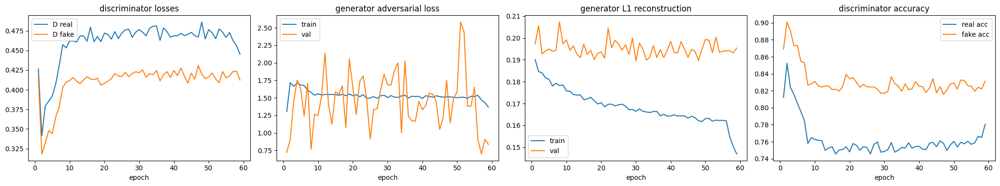

14 fixed-sample grids saved: ['epoch0001.png', 'epoch0005.png', 'epoch0010.png', 'epoch0015.png', 'epoch0020.png', 'epoch0025.png', 'epoch0030.png', 'epoch0035.png', 'epoch0040.png', 'epoch0045.png', 'epoch0050.png', 'epoch0055.png', 'epoch0060.png', 'epoch0065.png']


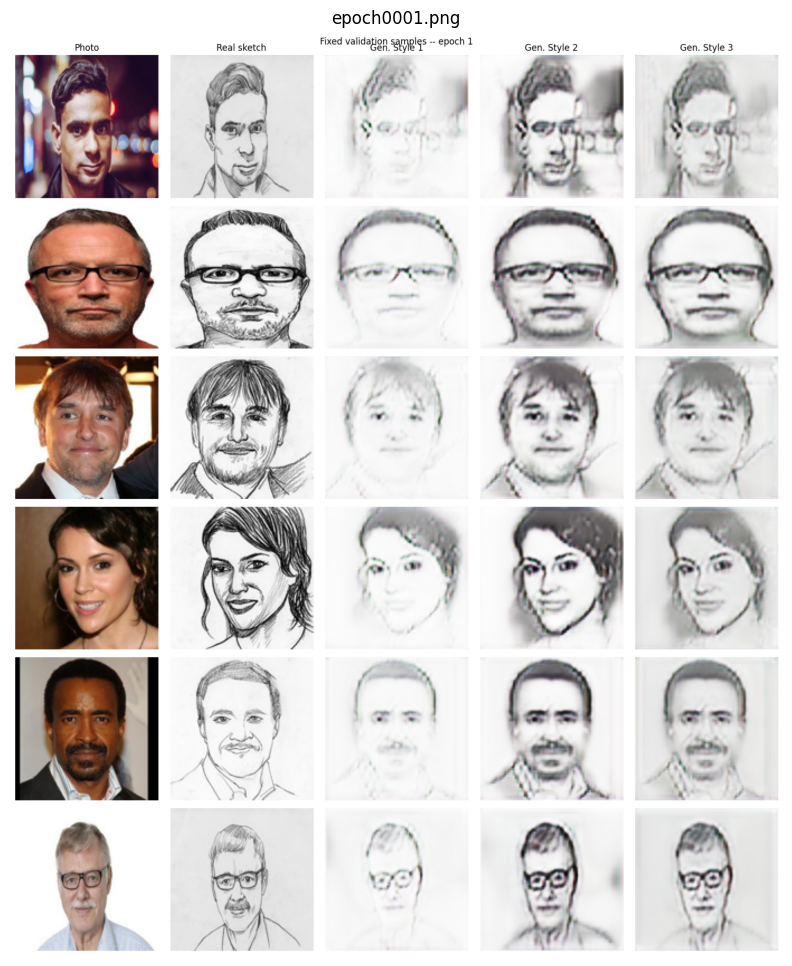

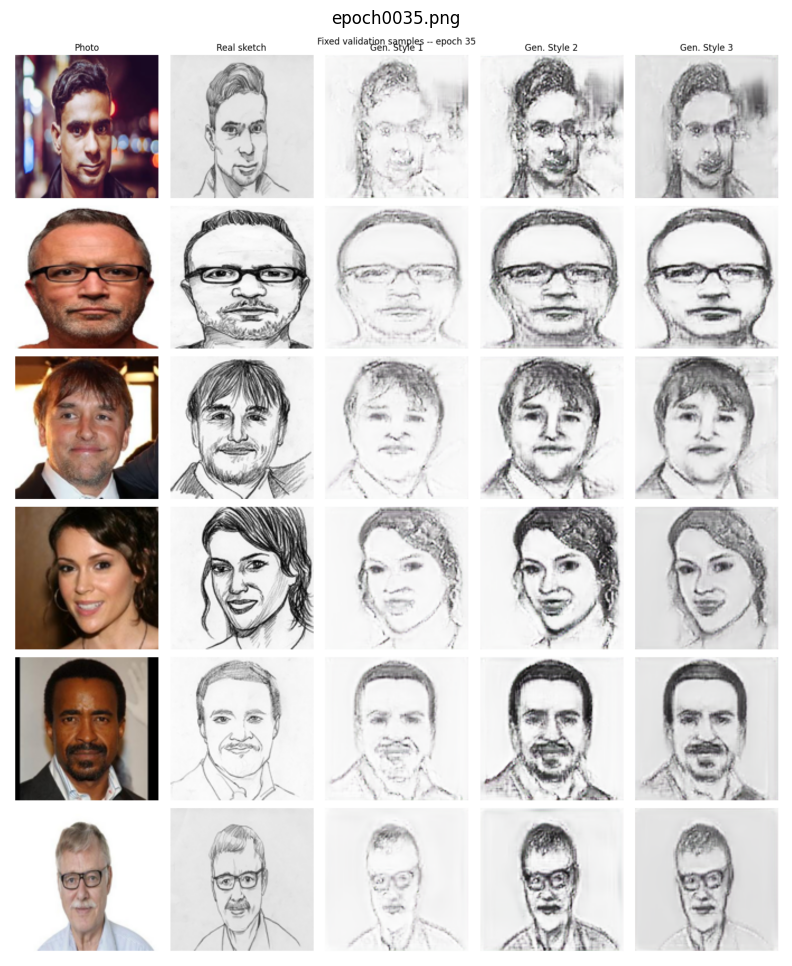

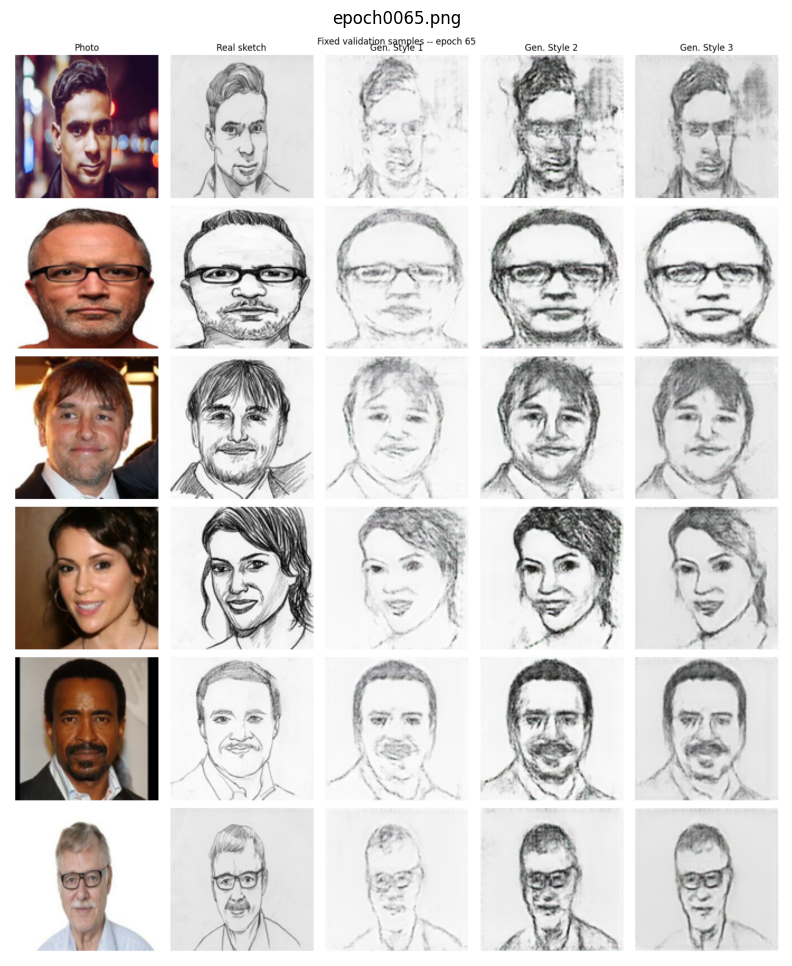

In [ ]:
# ============================================================
# Final training: the Optuna-selected configuration, full schedule.
# Resumable -- both G and D state (plus optimizers) are checkpointed every
# epoch, since resuming GAN training requires restoring BOTH networks in
# sync (restoring only G would restart the adversarial game from an
# undertrained D, undoing training balance).
# ============================================================

GAN_FINAL_EPOCHS = 150
GAN_PATIENCE = 25          # GANs plateau/fluctuate more than plain regression -- generous patience
SAMPLE_EVERY = 5
DIAGNOSTIC_EVERY = 5
GAN_CKPT_NAME = 'gan_best.pt'
GAN_CKPT_LAST_NAME = 'gan_last.pt'

g_lr = GAN_BEST_PARAMS['g_lr']
d_lr = GAN_BEST_PARAMS['d_lr']
batch_size = GAN_BEST_PARAMS['batch_size']
base_channels = GAN_BEST_PARAMS['base_channels']
dropout = GAN_BEST_PARAMS['dropout']
style_embed_dim = GAN_BEST_PARAMS['style_embed_dim']
lambda_l1 = GAN_BEST_PARAMS['lambda_l1']

set_seed(SEED)
G = StyleConditionedUNetGenerator(base_channels=base_channels, style_embed_dim=style_embed_dim,
                                   dropout=dropout).to(DEVICE)
D = PatchGANDiscriminator(base_channels=base_channels, style_embed_dim=style_embed_dim).to(DEVICE)
g_opt = torch.optim.Adam(G.parameters(), lr=g_lr, betas=(0.5, 0.999))
d_opt = torch.optim.Adam(D.parameters(), lr=d_lr, betas=(0.5, 0.999))

# Increased steps slightly to allow G to confidently drop below the 0.05 threshold
overfit_sanity_check_gan(lambda: StyleConditionedUNetGenerator(
    base_channels=base_channels, style_embed_dim=style_embed_dim, dropout=0.0), n_steps=750)

PRETRAIN_CKPT = 'gan_pretrained_G.pt'
if find_file(PRETRAIN_CKPT) is not None:
    try:
        G.load_state_dict(torch.load(find_file(PRETRAIN_CKPT), map_location=DEVICE)['g_state'])
        print('Loaded existing L1-pretrained generator -- skipping pretrain.')
    except Exception as e:
        print(f'Existing pretrain checkpoint is incompatible: {e}. Re-running pretrain.')
        pretrain_loader = make_loader(train_ds, batch_size, shuffle=True)
        pretrain_generator_l1(G, pretrain_loader, epochs=10, lr=g_lr, device=DEVICE)
        save_checkpoint({'g_state': G.state_dict()}, PRETRAIN_CKPT)
else:
    pretrain_loader = make_loader(train_ds, batch_size, shuffle=True)
    pretrain_generator_l1(G, pretrain_loader, epochs=10, lr=g_lr, device=DEVICE)
    save_checkpoint({'g_state': G.state_dict()}, PRETRAIN_CKPT)
    print('Generator L1-pretrained and checkpointed. Starting adversarial training from this point.')

start_epoch = 1
best_val_loss = float('inf')
epochs_no_improve = 0
history = []

resume_path = find_file(GAN_CKPT_LAST_NAME)
if resume_path is not None:
    try:
        ckpt = torch.load(resume_path, map_location=DEVICE)
        G.load_state_dict(ckpt['g_state'])
        D.load_state_dict(ckpt['d_state'])
        g_opt.load_state_dict(ckpt['g_opt_state'])
        d_opt.load_state_dict(ckpt['d_opt_state'])
        start_epoch = ckpt['epoch'] + 1
        best_val_loss = ckpt['best_val_loss']
        epochs_no_improve = ckpt['epochs_no_improve']
        history = ckpt.get('history', [])
        print(f'Resuming from {resume_path}, epoch {start_epoch}, best_val_loss {best_val_loss:.4f}')
    except Exception as e:
        print(f'Could not load resume checkpoint completely due to structure changes: {e}. Starting fresh.')
        start_epoch = 1
        best_val_loss = float('inf')
        epochs_no_improve = 0
        history = []
else:
    print('Starting GAN training from scratch.')

train_loader = make_loader(train_ds, batch_size, shuffle=True)
val_loader = make_loader(val_ds, batch_size, shuffle=False, drop_last=False)

if start_epoch > GAN_FINAL_EPOCHS:
    print(f'\u2705 Training already complete (epoch {start_epoch-1}/{GAN_FINAL_EPOCHS}). Skipping.')

for epoch in range(start_epoch, GAN_FINAL_EPOCHS + 1):
    t0 = time.time()
    train_metrics = train_one_epoch_gan(G, D, train_loader, g_opt, d_opt, lambda_l1, DEVICE)
    val_metrics = evaluate_gan(G, D, val_loader, lambda_l1, DEVICE)

    history.append({'epoch': epoch, **{f'train_{k}': v for k, v in train_metrics.items()},
                     **{f'val_{k}': v for k, v in val_metrics.items()}, 'time_s': time.time() - t0})
    print(f"[gan] epoch {epoch:03d} | d_real {train_metrics['d_real']:.4f} d_fake {train_metrics['d_fake']:.4f} "
          f"| g_adv {train_metrics['g_adv']:.4f} g_recon {train_metrics['g_recon']:.4f} "
          f"| val_recon {val_metrics['g_recon']:.4f} "
          f"| D_acc(real/fake) {train_metrics['d_real_acc']:.2f}/{train_metrics['d_fake_acc']:.2f} "
          f"| {time.time()-t0:.1f}s")

    check_discriminator_balance(train_metrics)

    if epoch % SAMPLE_EVERY == 0 or epoch == 1:
        path = log_fixed_samples(G, epoch, val_ds, FIXED_VAL_INDICES, SAMPLE_DIR)
        print(f'  saved sample grid: {path}')

    if epoch % DIAGNOSTIC_EVERY == 0:
        check_mode_collapse(G, val_ds, style_idx=0, n_images=8)

    improved = val_metrics['g_recon'] < best_val_loss - 1e-5
    if improved:
        best_val_loss = val_metrics['g_recon']
        epochs_no_improve = 0
        save_checkpoint({'g_state': G.state_dict(),
                          'config': {'base_channels': base_channels, 'style_embed_dim': style_embed_dim,
                                     'dropout': dropout, 'img_size': IMG_SIZE},
                          'epoch': epoch, 'val_recon': best_val_loss}, GAN_CKPT_NAME)
        if epoch == start_epoch:
            verify_checkpoint(GAN_CKPT_NAME)
    else:
        epochs_no_improve += 1

    save_checkpoint({'g_state': G.state_dict(), 'd_state': D.state_dict(),
                      'g_opt_state': g_opt.state_dict(), 'd_opt_state': d_opt.state_dict(),
                      'config': {'base_channels': base_channels, 'style_embed_dim': style_embed_dim,
                                 'dropout': dropout, 'img_size': IMG_SIZE},
                      'epoch': epoch, 'best_val_loss': best_val_loss, 'epochs_no_improve': epochs_no_improve,
                      'history': history}, GAN_CKPT_LAST_NAME)

    if epochs_no_improve >= GAN_PATIENCE:
        print(f'Early stopping at epoch {epoch} (no improvement in val_recon for {GAN_PATIENCE} epochs).')
        break

with open(os.path.join(RESULTS_DIR, 'gan_training_history.json'), 'w') as f:
    json.dump(history, f, indent=2)

# reload best generator for evaluation/export
best_path = find_file(GAN_CKPT_NAME)
best_ckpt = torch.load(best_path, map_location=DEVICE)
G = StyleConditionedUNetGenerator(**best_ckpt['config']).to(DEVICE)
G.load_state_dict(best_ckpt['g_state'])
G.eval()
print("Loaded best generator, val_recon =", best_ckpt["val_recon"])

# Architecture summary of the final configuration and training curves
import pandas as pd
print(f'Generator params: {sum(p.numel() for p in G.parameters()):,} | Discriminator params: {sum(p.numel() for p in D.parameters()):,} '
      f'| style embedding dim: {style_embed_dim} (used in both G and D)')
h = pd.DataFrame(history)
fig, axes = plt.subplots(1, 4, figsize=(21, 4))
axes[0].plot(h['epoch'], h['train_d_real'], label='D real'); axes[0].plot(h['epoch'], h['train_d_fake'], label='D fake'); axes[0].set_title('discriminator losses'); axes[0].legend()
axes[1].plot(h['epoch'], h['train_g_adv'], label='train'); axes[1].plot(h['epoch'], h['val_g_adv'], label='val'); axes[1].set_title('generator adversarial loss'); axes[1].legend()
axes[2].plot(h['epoch'], h['train_g_recon'], label='train'); axes[2].plot(h['epoch'], h['val_g_recon'], label='val'); axes[2].set_title('generator L1 reconstruction'); axes[2].legend()
axes[3].plot(h['epoch'], h['train_d_real_acc'], label='real acc'); axes[3].plot(h['epoch'], h['train_d_fake_acc'], label='fake acc'); axes[3].set_title('discriminator accuracy'); axes[3].legend()
for a in axes: a.set_xlabel('epoch')
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, 'gan_training_curves.png'), dpi=120, bbox_inches='tight'); plt.show()

# Progress on the same fixed validation photos (saved every 5 epochs during training)
_snaps = sorted(glob.glob(os.path.join(SAMPLE_DIR, 'epoch*.png')))
print(len(_snaps), 'fixed-sample grids saved:', [os.path.basename(p) for p in _snaps])
for p in [_snaps[0], _snaps[len(_snaps) // 2], _snaps[-1]] if _snaps else []:
    plt.figure(figsize=(12, 12)); plt.imshow(plt.imread(p)); plt.axis('off'); plt.title(os.path.basename(p)); plt.show()

## Final eval

=== Test set metrics by style (L1 in [-1,1] space; SSIM / PSNR on [0,1] images) ===
             l1            ssim             psnr        
           mean     std    mean     std     mean     std
style                                                   
Style 1  0.2040  0.1054  0.4637  0.1402  15.9306  3.2939
Style 2  0.3159  0.0634  0.3913  0.0817  12.1416  1.2359
Style 3  0.1269  0.0457  0.6203  0.0717  18.8723  1.7374
Overall: {'l1': 0.2414, 'ssim': 0.4442, 'psnr': 14.6799} | test pairs: 1046


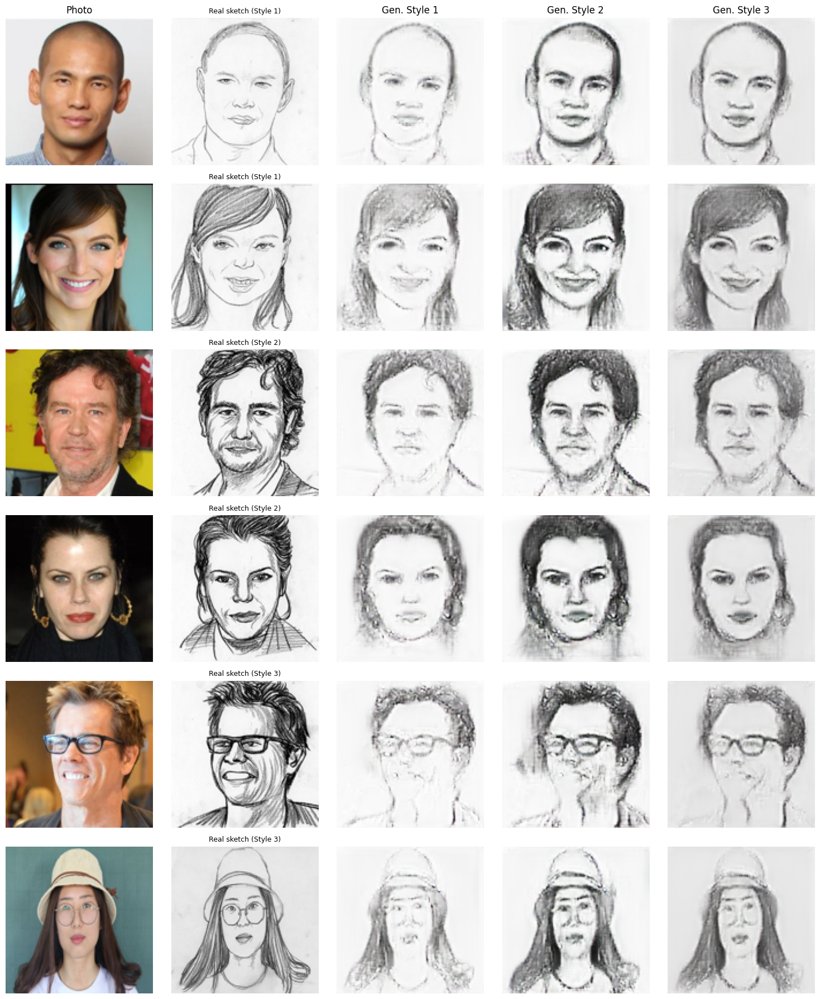

Saved to /content/drive/MyDrive/task4_face2sketch/results/test_gallery.png


In [ ]:
# ============================================================
# Final evaluation on the official, untouched test set.
# ============================================================

from pytorch_msssim import ssim as ssim_metric

@torch.no_grad()
def evaluate_l1_by_style(G, dataset, device=DEVICE):
    loader = make_loader(dataset, 32, shuffle=False, drop_last=False)
    records = []
    for batch in loader:
        x = batch['photo'].to(device)
        y = batch['sketch'].to(device)
        s = batch['style'].to(device)
        y_fake = G(x, s)
        l1_ps = F.l1_loss(y_fake, y, reduction='none').mean(dim=[1, 2, 3])
        y01, f01 = (y + 1) / 2, (y_fake.clamp(-1, 1) + 1) / 2
        ssim_ps = ssim_metric(f01, y01, data_range=1.0, size_average=False)
        psnr_ps = 10 * torch.log10(1.0 / (((f01 - y01) ** 2).mean(dim=[1, 2, 3]) + 1e-8))
        for i in range(x.size(0)):
            records.append({'style': STYLE_NAMES[s[i].item()], 'l1': l1_ps[i].item(),
                            'ssim': ssim_ps[i].item(), 'psnr': psnr_ps[i].item()})
    return records


import pandas as pd
test_records_l1 = evaluate_l1_by_style(G, test_ds)
test_df = pd.DataFrame(test_records_l1)
print('=== Test set metrics by style (L1 in [-1,1] space; SSIM / PSNR on [0,1] images) ===')
print(test_df.groupby('style')[['l1', 'ssim', 'psnr']].agg(['mean', 'std']).round(4).to_string())
print('Overall:', test_df[['l1', 'ssim', 'psnr']].mean().round(4).to_dict(), '| test pairs:', len(test_df))
test_df.to_csv(os.path.join(RESULTS_DIR, 'test_l1_by_style.csv'), index=False)

# ---- qualitative gallery: several test photos x all 3 styles ----
def show_test_gallery(dataset, n=6, save_name='test_gallery.png'):
    # two test photos of every ground-truth style
    idxs = [i for k in range(3) for i in [j for j, r in enumerate(dataset.records) if r['style'] == k][:n // 3]]
    fig, axes = plt.subplots(len(idxs), 5, figsize=(15, 3 * len(idxs)))
    col_titles = ['Photo', 'Real sketch', 'Gen. Style 1', 'Gen. Style 2', 'Gen. Style 3']
    with torch.no_grad():
        for row, idx in enumerate(idxs):
            item = dataset[idx]
            photo = item['photo'].unsqueeze(0).to(DEVICE)
            imgs = [(photo[0].cpu() + 1) / 2, (item['sketch'] + 1) / 2]
            for style_idx in range(3):
                s = torch.tensor([style_idx], device=DEVICE)
                fake = G(photo, s)[0].clamp(-1, 1).cpu()
                imgs.append((fake + 1) / 2)
            for col, img in enumerate(imgs):
                axes[row, col].imshow(img.permute(1, 2, 0).numpy())
                axes[row, col].axis('off')
                if row == 0:
                    axes[row, col].set_title(col_titles[col])
            axes[row, 1].set_title(f"Real sketch ({STYLE_NAMES[item['style'].item()]})", fontsize=9)
    plt.tight_layout()
    out_path = os.path.join(RESULTS_DIR, save_name)
    plt.savefig(out_path, dpi=110, bbox_inches='tight')
    plt.show()
    print('Saved to', out_path)


show_test_gallery(test_ds, n=6)


## Failure cases: worst outputs, style confusion, mode collapse

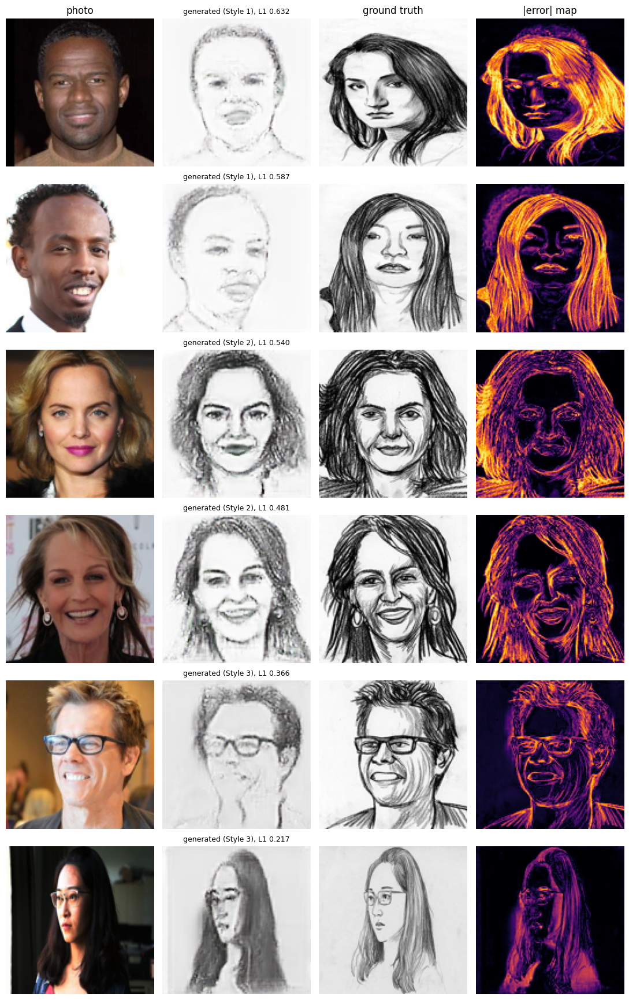

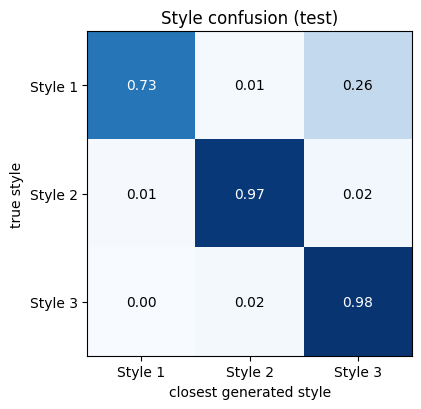

[mode-collapse check, style=0] real_std=0.4322 fake_std=0.1998 ratio=0.46 -> healthy (varies with input)
[mode-collapse check, style=1] real_std=0.4322 fake_std=0.3542 ratio=0.82 -> healthy (varies with input)
[mode-collapse check, style=2] real_std=0.4322 fake_std=0.2428 ratio=0.56 -> healthy (varies with input)


In [ ]:
# Highest-L1 test outputs (two per style) with absolute error maps
_worst = test_df.sort_values('l1', ascending=False).groupby('style').head(2).index.tolist()
fig, axes = plt.subplots(len(_worst), 4, figsize=(11, 2.9 * len(_worst)))
with torch.no_grad():
    for r, i in enumerate(_worst):
        it = test_ds[i]
        x = it['photo'].unsqueeze(0).to(DEVICE); s = it['style'].view(1).to(DEVICE)
        fake = (G(x, s)[0].clamp(-1, 1).cpu() + 1) / 2; real = (it['sketch'] + 1) / 2
        for c, img in enumerate([(it['photo'] + 1) / 2, fake, real]):
            axes[r, c].imshow(img.permute(1, 2, 0).numpy()); axes[r, c].axis('off')
        axes[r, 3].imshow((fake - real).abs().mean(0).numpy(), cmap='inferno', vmin=0, vmax=1); axes[r, 3].axis('off')
        axes[r, 1].set_title(f"generated ({test_df.loc[i, 'style']}), L1 {test_df.loc[i, 'l1']:.3f}", fontsize=9)
for c, t in enumerate(['photo', None, 'ground truth', '|error| map']):
    if t: axes[0, c].set_title(t)
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, 'failure_cases.png'), dpi=120, bbox_inches='tight'); plt.show()

# Style confusion: is the sketch generated with the TRUE style closer to the ground truth than the other two styles?
_conf = np.zeros((3, 3))
with torch.no_grad():
    for b in make_loader(test_ds, 32, shuffle=False, drop_last=False):
        x, y, s = b['photo'].to(DEVICE), b['sketch'].to(DEVICE), b['style']
        d = torch.stack([(G(x, torch.full_like(s, k).to(DEVICE)) - y).abs().mean(dim=[1, 2, 3]) for k in range(3)], 1).cpu()
        for t, p in zip(s.tolist(), d.argmin(1).tolist()):
            _conf[t, p] += 1
_conf = _conf / _conf.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(4.8, 4.2))
ax.imshow(_conf, cmap='Blues', vmin=0, vmax=1)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f'{_conf[i, j]:.2f}', ha='center', va='center', color='white' if _conf[i, j] > .5 else 'black')
ax.set_xticks(range(3)); ax.set_xticklabels(STYLE_NAMES); ax.set_yticks(range(3)); ax.set_yticklabels(STYLE_NAMES)
ax.set_xlabel('closest generated style'); ax.set_ylabel('true style'); ax.set_title('Style confusion (test)')
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, 'style_confusion.png'), dpi=120, bbox_inches='tight'); plt.show()

# Mode collapse check on test photos, for every style
for k in range(3):
    check_mode_collapse(G, test_ds, style_idx=k, n_images=16)

**Failure analysis.**
* **Artifacts**: the largest errors come from photos unlike most training faces, for example strong lighting, accessories, unusual backgrounds or non-frontal poses. Hair is the largest error region in every style, because the artist draws strands freely and they cannot be predicted pixel-exactly.
* **Style confusion**: the matrix shows how often the requested style is the one closest to the ground truth. Off-diagonal values mean that style is not fully separated. Style 3 has only 46 test images, so its numbers are noisy.
* **Mode collapse**: a diversity ratio well above 0.25 means the outputs change with the input photo, so there is no collapse. The λ_L1 reconstruction term keeps the generator tied to the input.

## ONNX export

In [ ]:
# ============================================================
# Export the GENERATOR ONLY to ONNX -- per the assignment, the
# discriminator is a training-only component and is not needed at
# inference. Takes a photo and a style index; outputs a sketch.
# ============================================================

G.eval().cpu()
dummy_photo = torch.randn(1, 3, IMG_SIZE, IMG_SIZE)
dummy_style = torch.tensor([0])
gen_onnx_path = os.path.join(ONNX_DIR, 'face2sketch_generator.onnx')

torch.onnx.export(
    G, (dummy_photo, dummy_style), gen_onnx_path,
    input_names=['photo', 'style_idx'], output_names=['sketch'],
    dynamic_axes={'photo': {0: 'batch'}, 'style_idx': {0: 'batch'}, 'sketch': {0: 'batch'}},
    opset_version=17, dynamo=False,
)
G.to(DEVICE)

import onnx
onnx.checker.check_model(onnx.load(gen_onnx_path))
print('Generator exported and validated at:', gen_onnx_path)

with open(os.path.join(ONNX_DIR, 'app_config.json'), 'w') as f:
    json.dump({
        'img_size': IMG_SIZE,
        'input_range_photo': '[-1,1] float32, CHW, RGB (normalize: pixel/127.5 - 1)',
        'output_range_sketch': '[-1,1] float32, CHW, RGB (display: (pixel+1)*127.5)',
        'style_names': STYLE_NAMES,
        'style_input': 'int64 scalar per image: 0=Style 1, 1=Style 2, 2=Style 3',
        'onnx_file': 'face2sketch_generator.onnx',
    }, f, indent=2)

import onnxruntime as ort
sess = ort.InferenceSession(gen_onnx_path, providers=['CPUExecutionProvider'])
t0 = time.time()
out = sess.run(None, {'photo': dummy_photo.numpy(), 'style_idx': dummy_style.numpy()})
inference_ms = (time.time() - t0) * 1000
print(f'ONNX Runtime check OK: output shape {out[0].shape}, inference time {inference_ms:.1f} ms')

# Verify ONNX Runtime output against PyTorch on real test photos for all three styles
_x = torch.stack([test_ds[i]['photo'] for i in range(0, 1040, 65)])
G.eval().cpu()
for k in range(3):
    _s = torch.full((len(_x),), k, dtype=torch.long)
    with torch.no_grad():
        _pt = G(_x, _s).numpy()
    _ox = sess.run(None, {'photo': _x.numpy(), 'style_idx': _s.numpy()})[0]
    print(f'{STYLE_NAMES[k]}: max |diff| = {np.abs(_pt - _ox).max():.2e}, mean |diff| = {np.abs(_pt - _ox).mean():.2e}')
G.to(DEVICE)

/tmp/ipykernel_11642/890600862.py:12: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(
/usr/local/lib/python3.13/dist-packages/torch/onnx/_internal/torchscript_exporter/symbolic_opset9.py:2822: UserWarning: ONNX export mode is set to TrainingMode.EVAL, but operator 'instance_norm' is set to train=True. Exporting with train=True.
  symbolic_helper.check_training_mode(use_input_stats, "instance_norm")


Generator exported and validated at: /content/drive/MyDrive/task4_face2sketch/onnx_export/face2sketch_generator.onnx
ONNX Runtime check OK: output shape (1, 3, 128, 128), inference time 42.0 ms
Style 1: max |diff| = 3.35e-06, mean |diff| = 1.37e-07
Style 2: max |diff| = 4.00e-06, mean |diff| = 1.73e-07
Style 3: max |diff| = 2.65e-06, mean |diff| = 1.20e-07


StyleConditionedUNetGenerator(
  (style_embed): Embedding(3, 16)
  (d1): DownBlock(
    (net): Sequential(
      (0): Conv2d(19, 48, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
      (1): LeakyReLU(negative_slope=0.2, inplace=True)
    )
  )
  (d2): DownBlock(
    (net): Sequential(
      (0): Conv2d(48, 96, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
      (1): InstanceNorm2d(96, eps=1e-05, momentum=0.1, affine=True, track_running_stats=False)
      (2): LeakyReLU(negative_slope=0.2, inplace=True)
    )
  )
  (d3): DownBlock(
    (net): Sequential(
      (0): Conv2d(96, 192, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
      (1): InstanceNorm2d(192, eps=1e-05, momentum=0.1, affine=True, track_running_stats=False)
      (2): LeakyReLU(negative_slope=0.2, inplace=True)
    )
  )
  (d4): DownBlock(
    (net): Sequential(
      (0): Conv2d(192, 384, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
      (1): InstanceNorm2d(384, eps=1e-05, momentum=0.1, affine=True, t

## Experiment tracking (MLflow)

In [ ]:
# Log the GAN configuration, losses, Optuna trials, test metrics, checkpoint, ONNX and figures to MLflow
import mlflow
MLFLOW_DIR = '/content/drive/MyDrive/mlflow_genai'
os.makedirs(MLFLOW_DIR, exist_ok=True)
mlflow.set_tracking_uri(f'sqlite:///{MLFLOW_DIR}/mlflow.db')
EXP, RUN = 'Task4-Face2Sketch-cGAN', 'cgan_final'
if mlflow.get_experiment_by_name(EXP) is None:
    mlflow.create_experiment(EXP, artifact_location=os.path.join(MLFLOW_DIR, 'artifacts', EXP))
_exp = mlflow.set_experiment(EXP)
if len(mlflow.search_runs([_exp.experiment_id], filter_string=f"tags.mlflow.runName = '{RUN}'")):
    print(f'{RUN} already logged in MLflow.')
else:
    with mlflow.start_run(run_name=RUN):
        mlflow.log_params({**GAN_BEST_PARAMS, 'max_epochs': GAN_FINAL_EPOCHS, 'patience': GAN_PATIENCE, 'g_pretrain_epochs': 10})
        for rec in history:
            mlflow.log_metrics({k: float(v) for k, v in rec.items() if k != 'epoch'}, step=int(rec['epoch']))
        for st, grp in test_df.groupby('style'):
            mlflow.log_metrics({f"test_{st.replace(' ', '')}_{m}": float(grp[m].mean()) for m in ['l1', 'ssim', 'psnr']})
        mlflow.log_metrics({f'test_overall_{m}': float(test_df[m].mean()) for m in ['l1', 'ssim', 'psnr']})
        _op = os.path.join(RESULTS_DIR, 'gan_optuna_all_trials.json')
        if os.path.exists(_op):
            for t in json.load(open(_op)):
                with mlflow.start_run(run_name=f"optuna_trial_{t['number']}", nested=True):
                    mlflow.log_params(t['params']); mlflow.set_tag('state', t['state'])
                    if t['value'] is not None:
                        mlflow.log_metric('objective', t['value'])
        for f in glob.glob(os.path.join(RESULTS_DIR, '*.png')) + glob.glob(os.path.join(RESULTS_DIR, '*.csv')) + glob.glob(os.path.join(RESULTS_DIR, '*.json')):
            mlflow.log_artifact(f, 'results')
        for f in sorted(glob.glob(os.path.join(SAMPLE_DIR, '*.png'))):
            mlflow.log_artifact(f, 'fixed_validation_samples')
        mlflow.log_artifact(find_file('gan_best.pt'), 'checkpoint')
        mlflow.log_artifact(gen_onnx_path, 'onnx')
    print('Logged to MLflow:', mlflow.get_tracking_uri())

Logged to MLflow: sqlite:////content/drive/MyDrive/mlflow_genai/mlflow.db


In [ ]:
# Open the MLflow UI (all four tasks log to the same store) -- useful for the demo video
import subprocess
_help = subprocess.run(['mlflow', 'ui', '--help'], capture_output=True, text=True).stdout
_cmd = ['mlflow', 'ui', '--backend-store-uri', mlflow.get_tracking_uri(), '--host', '0.0.0.0', '--port', '5000']
if '--allowed-hosts' in _help:
    _cmd += ['--allowed-hosts', '*']
subprocess.Popen(_cmd, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
time.sleep(10)
from google.colab.output import eval_js
print('MLflow UI:', eval_js('google.colab.kernel.proxyPort(5000)'))

MLflow UI: https://5000-gpu-t4-s-kkb-ass1c2-jabtdf2gsjgd-c.asia-southeast1-2.prod.colab.dev


## App preview

Loaded generator fresh from /content/drive/MyDrive/task4_face2sketch/checkpoints/gan_best.pt (val_recon=0.1895)


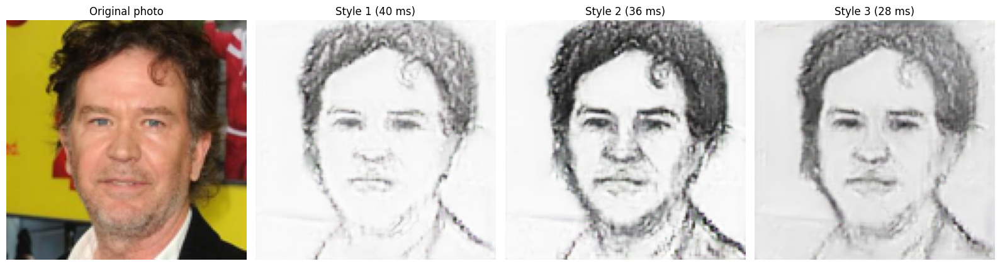

Saved app preview to /content/drive/MyDrive/task4_face2sketch/results/app_preview.png
Downloadable sketches saved to /content/drive/MyDrive/task4_face2sketch/results


Saving Profile.png to Profile.png


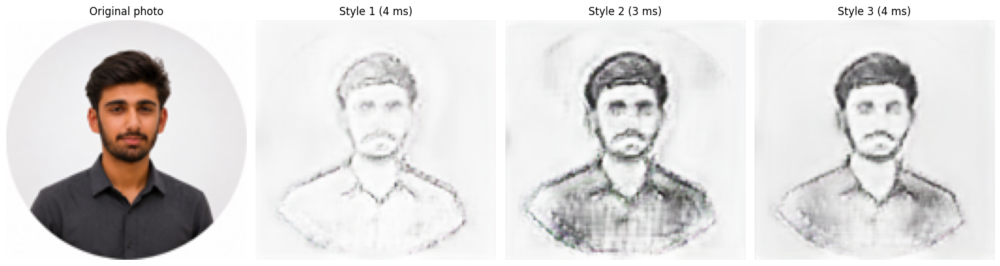

Saved app preview to /content/drive/MyDrive/task4_face2sketch/results/app_preview.png
Downloadable sketches saved to /content/drive/MyDrive/task4_face2sketch/results


In [ ]:
# ============================================================
# FINAL TEST: reload the generator strictly from its saved Drive
# checkpoint and preview the "Face-to-Sketch Generator" app -- upload a
# photo, pick a style, generate, show photo + sketch side by side, save a
# downloadable file. This is also usable directly in Colab: run the upload
# cell to try your own photo.
# ============================================================

_best_path = find_file('gan_best.pt')
assert _best_path is not None, 'gan_best.pt not found -- run the final training cell first.'
_ckpt = torch.load(_best_path, map_location=DEVICE)
loaded_G = StyleConditionedUNetGenerator(**_ckpt['config']).to(DEVICE)
loaded_G.load_state_dict(_ckpt['g_state'])
loaded_G.eval()
print(f'Loaded generator fresh from {_best_path} (val_recon={_ckpt["val_recon"]:.4f})')


@torch.no_grad()
def generate_sketch(photo_pil, style_idx, G=loaded_G, device=DEVICE):
    """photo_pil: a PIL image (any size/mode) -- exactly what an uploaded
    or webcam-captured photo would be in the app."""
    photo = photo_pil.convert('RGB').resize((IMG_SIZE, IMG_SIZE), Image.BICUBIC)
    x = to_tensor_pm1(photo).unsqueeze(0).to(device)
    s = torch.tensor([style_idx], device=device)
    t0 = time.time()
    y = G(x, s)
    inference_ms = (time.time() - t0) * 1000
    sketch_np = ((y[0].clamp(-1, 1).cpu() + 1) / 2 * 255).byte().permute(1, 2, 0).numpy()
    return Image.fromarray(sketch_np), inference_ms


def show_app_preview(photo_pil, save_name='app_preview.png'):
    fig, axes = plt.subplots(1, 4, figsize=(16, 4.2))
    axes[0].imshow(photo_pil.resize((IMG_SIZE, IMG_SIZE)))
    axes[0].set_title('Original photo'); axes[0].axis('off')
    for i, style_idx in enumerate(range(3)):
        sketch, inference_ms = generate_sketch(photo_pil, style_idx)
        axes[i + 1].imshow(sketch)
        axes[i + 1].set_title(f'{STYLE_NAMES[style_idx]} ({inference_ms:.0f} ms)')
        axes[i + 1].axis('off')
        out_path = os.path.join(RESULTS_DIR, f'download_{STYLE_NAMES[style_idx].replace(" ", "")}.png')
        sketch.save(out_path)  # the "download result" option, as a saved file
    plt.tight_layout()
    preview_path = os.path.join(RESULTS_DIR, save_name)
    plt.savefig(preview_path, dpi=110, bbox_inches='tight')
    plt.show()
    print('Saved app preview to', preview_path)
    print('Downloadable sketches saved to', RESULTS_DIR)


# Preview using a real test-set photo (stand-in for an uploaded photo)
_preview_photo_path = test_records[0]['photo_path']
show_app_preview(Image.open(_preview_photo_path))

# To try your OWN photo in Colab, uncomment:
from google.colab import files
uploaded = files.upload()
my_photo = Image.open(list(uploaded.keys())[0])
show_app_preview(my_photo)
